# ITCS 6169/8169 — Computer Vision
## Assignment 2: ViT from scratch — supervised baseline vs. SSAT (self-supervised auxiliary task)

Everything trains from scratch on the provided 2,400 images only.

**SSAT (Liu et al., NeurIPS'21; lecture slides).** One shared transformer encoder, two streams, trained *jointly*:
- **Primary stream:** classify the (augmented) image from the full set of patch tokens.
- **Auxiliary stream:** take a second, differently augmented view, keep only a fraction of its patches (25% in the slides), and **reconstruct** the image from them with a small decoder (MAE-style).
- `loss = λ · L_cls + (1 − λ) · L_aux`. At test time only the primary stream is used; the decoder is thrown away.

**`λ = 1.0` switches the auxiliary task off, so it *is* the supervised ViT baseline** — same encoder, data, schedule and epochs. SSAT's gain is always measured against that run.

**Plan**
1. Controls: model size, a speed/shape check on the device, a look at the views and masks.
2. **Stage A — baseline fairness:** tune the *supervised* ViT's LR (3 runs), so SSAT is not compared against an untuned baseline.
3. **Stage B — SSAT ablations** at that LR (60 epochs each, one knob at a time): `λ` and the visible-patch ratio, plus a seed-repeat for noise.
4. Combine what clearly helped, then **final runs**: supervised ViT and SSAT, 100 epochs, 2 seeds each → validation → test once.
5. Side-by-side with the saved SigLIP-CNN and BYOL-CNN results.

Set `SMOKE_TEST = True` first. Ablation scores use the **mean of the last 5 validation accuracies** (less optimistic and less noisy than the best epoch).

> **128px finals-only mode.** This is the same notebook as the 64px version with `IMG_SIZE = 128`. All ablation / search cells are skipped; the configuration chosen at 64px is loaded from `checkpoints/` and trained at the higher resolution. Results and checkpoints get a `128px_` prefix, so nothing from the 64px runs is overwritten or reused. **Prerequisite:** the 64px notebook must have been run in the same project folder. Restart the kernel and check the GPU is free before starting.

In [1]:
# Core imports
from pathlib import Path
import random, time, copy, math, json, gc, threading, queue

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from PIL import Image

try:
    import torch_directml  # to allow for AMD gpu usage
    HAS_DML = torch_directml.is_available()
except ImportError:
    HAS_DML = False

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"DirectML available: {HAS_DML}")

PyTorch version: 2.4.1+cpu
CUDA available: False
DirectML available: True


In [2]:
PROJECT_ROOT = Path('.')
DATA_ROOT = PROJECT_ROOT / 'data'
TRAIN_ROOT = DATA_ROOT / 'train'
TEST_ROOT = DATA_ROOT / 'test'

print('Project root:', PROJECT_ROOT.resolve())
print('Training data:', TRAIN_ROOT)
print('Testing data:', TEST_ROOT)

Project root: D:\School\13 - Fall 2026\ITCS 6169\assignment2
Training data: data\train
Testing data: data\test


In [3]:
SEED = 0

def set_random_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def get_device():
    """CUDA if available, else DirectML (AMD GPU on Windows), else CPU."""
    if torch.cuda.is_available():
        return torch.device("cuda")
    if HAS_DML:
        return torch_directml.device()
    return torch.device("cpu")

set_random_seed(SEED)
device = get_device()
print('Device:', device)

Device: privateuseone:0


## Config

In [4]:
SMOKE_TEST = False   # True -> tiny runs, just to check the notebook runs end-to-end
IMG_SIZE = 128           # 64 = the tuned setting; any other size runs in FINALS_ONLY mode
PREFIX = ('smoke_' if SMOKE_TEST else '') + ('' if IMG_SIZE == 64 else f'{IMG_SIZE}px_')   # keeps smoke / other-resolution files separate
FINALS_ONLY = IMG_SIZE != 64   # skip all ablations; reuse the config selected by the 64px notebook
HIRES_SSL_BS = 64        # FINALS_ONLY: SSL batch size (a 128px batch of 128 image pairs may not fit in GPU memory)
HIRES_SSL_EPOCHS = 100   # FINALS_ONLY: SSL epochs (the 64px probe curves plateaued around epoch 100-120)

# Data
BATCH_SIZE = 32          # only used by the shared eval loaders
VAL_FRACTION = 0.20

# Mixup / CutMix on the PRIMARY stream (same recipe as A1)
MIXUP_ALPHA = 0.4
CUTMIX_ALPHA = 1.0
CUTMIX_PROB = 0.5

BASE_CFG = dict(
    lam=0.5,             # SSAT weight on the classification loss: loss = lam*CE + (1-lam)*recon.  lam=1.0 -> supervised ViT
    keep=0.25,           # fraction of patches VISIBLE to the auxiliary stream (slides: 25%)
    lr=5e-4, wd=0.05, bs=64, warmup=5, drop=0.1,
    crop_min=0.5, jitter=0.4, gray_p=0.2,          # augmentation of the auxiliary view (the primary view uses the A1 augmentation)
    patch=8,             # 64px / 8 = 8x8 = 64 patch tokens
    dim=192, depth=6, heads=3,                     # encoder (~2.7M params)
    dec_dim=128, dec_depth=2, dec_heads=4,         # decoder, used only during training
)
BASE_CFG['patch'] = IMG_SIZE // 8     # keep 8x8 = 64 tokens at any resolution (64px: patch 8, 128px: patch 16)

LR_GRID = [2.5e-4, 1e-3]                            # Stage A: supervised-ViT LR candidates (base LR is also run)
GRID = {                                            # Stage B: SSAT knobs, one at a time
    'lam':  [0.8, 0.2],
    'keep': [0.125, 0.5],
}

# ---- Budget ----
ABL_EPOCHS = 60
SCORE_LAST = 5           # ablation score = mean of the last 5 validation accuracies
MIN_GAIN = 0.02          # adopt a change only if it beats its reference by >= 2 pts (validation noise ~1.5 pts)
MANUAL_OVERRIDE = {}     # e.g. {'lam': 0.8}
RUN_NOISE_CHECK = True   # also run the SSAT base with seed 1
FORCE_RERUN = False      # False -> finished ablation runs are loaded from JSON (resume after a crash)

FINAL_EPOCHS = 100
FINAL_SEEDS = (0, 1)

if SMOKE_TEST:
    ABL_EPOCHS = FINAL_EPOCHS = 2
    SCORE_LAST = 2
    BASE_CFG['warmup'] = 1
    LR_GRID = LR_GRID[:1]
    GRID = {'lam': [0.8]}
    FINAL_SEEDS = (0,)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

## Data

In [5]:
# Mixup / CutMix helpers (from A1)
def mixup_data(x, y, alpha=0.2):
    '''Returns mixed inputs, pairs of targets, and lambda.'''
    if alpha > 0:
        lam = np.random.beta(alpha, alpha)
    else:
        lam = 1.0

    batch_size = x.size(0)
    index = torch.randperm(batch_size).to(x.device)

    mixed_x = lam * x + (1 - lam) * x[index]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def cutmix_data(x, y, alpha=1.0):
    lam = np.random.beta(alpha, alpha)
    index = torch.randperm(x.size(0), device=x.device)
    H, W = x.size(2), x.size(3)

    cut_ratio = np.sqrt(1.0 - lam)
    cut_h, cut_w = int(H * cut_ratio), int(W * cut_ratio)
    cy, cx = np.random.randint(H), np.random.randint(W)
    y1, y2 = np.clip(cy - cut_h // 2, 0, H), np.clip(cy + cut_h // 2, 0, H)
    x1, x2 = np.clip(cx - cut_w // 2, 0, W), np.clip(cx + cut_w // 2, 0, W)

    x = x.clone()
    x[:, :, y1:y2, x1:x2] = x[index, :, y1:y2, x1:x2]
    lam = 1.0 - ((y2 - y1) * (x2 - x1) / (H * W))   # correct lam for the clipped box
    return x, y, y[index], lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

def random_grayscale_rgb(img):
    # Augment only on training; validation/test should stay clean.
    if random.random() < 0.5:
        gray = img.convert("L")
        return gray.convert("RGB")
    return img

class Prefetch:
    """Runs a DataLoader in a background thread so augmentation overlaps with GPU compute."""
    def __init__(self, loader, depth=3):
        self.loader, self.depth = loader, depth

    def __len__(self):
        return len(self.loader)

    def __iter__(self):
        q = queue.Queue(maxsize=self.depth)
        done = object()
        def work():
            try:
                for item in self.loader:
                    q.put(item)
            except Exception as e:          # hand errors to the main thread instead of hanging it
                q.put(e)
            q.put(done)
        threading.Thread(target=work, daemon=True).start()
        while True:
            item = q.get()
            if item is done:
                return
            if isinstance(item, Exception):
                raise item
            yield item

In [6]:
# Fine-tuning augmentation (from A1) and clean eval preprocessing
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
    transforms.Lambda(random_grayscale_rgb),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

def build_ssl_aug(crop_min=0.3, jitter=0.4, gray_p=0.2):
    """SSL view augmentation; the three arguments are ablation knobs."""
    return transforms.Compose([
        transforms.RandomResizedCrop(IMG_SIZE, scale=(crop_min, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomApply([transforms.ColorJitter(jitter, jitter, jitter, jitter / 4)], p=0.8),
        transforms.RandomGrayscale(p=gray_p),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ])

ssl_aug = build_ssl_aug(BASE_CFG['crop_min'], BASE_CFG['jitter'], BASE_CFG['gray_p'])

class TransformSubset(torch.utils.data.Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        image, label = self.subset[idx]
        if self.transform is not None:
            image = self.transform(image)
        return image, label

class TwoView(torch.utils.data.Dataset):
    """Two independently augmented views of the same image (the label is returned but never used by SSL)."""
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        image, label = self.subset[idx]
        return self.transform(image), self.transform(image), label

In [7]:
base_train_dataset = datasets.ImageFolder(TRAIN_ROOT)
class_names = base_train_dataset.classes
num_classes = len(class_names)

# decode + resize once; the split below uses a seeded generator so it is identical in every run
cached_train = [(img.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), y) for img, y in base_train_dataset]

val_size = int(round(len(base_train_dataset) * VAL_FRACTION))
train_size = len(base_train_dataset) - val_size
generator = torch.Generator().manual_seed(SEED)
train_subset, val_subset = random_split(cached_train, [train_size, val_size], generator=generator)

train_dataset = TransformSubset(train_subset, train_transform)
val_dataset = TransformSubset(val_subset, eval_transform)
test_dataset = datasets.ImageFolder(TEST_ROOT, transform=eval_transform)

pin = torch.cuda.is_available()
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=pin)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=pin)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=pin)

def make_ssl_loader(bs=None, aug=None):
    """Two-view loader over the TRAIN split only (never val/test). drop_last keeps batches full."""
    return Prefetch(DataLoader(TwoView(train_subset, aug or ssl_aug), batch_size=bs or BASE_CFG['bs'],
                               shuffle=True, drop_last=True, num_workers=0, pin_memory=pin))

print(f'Classes ({num_classes}): {class_names}')
print(f'Train: {len(train_dataset)} | Validation: {len(val_dataset)} | Test: {len(test_dataset)}')

Classes (16): ['Bedroom', 'Coast', 'Flower', 'Forest', 'Highway', 'Industrial', 'InsideCity', 'Kitchen', 'LivingRoom', 'Mountain', 'Office', 'OpenCountry', 'Store', 'Street', 'Suburb', 'TallBuilding']
Train: 1920 | Validation: 480 | Test: 400


In [8]:
class PairDS(torch.utils.data.Dataset):
    """Two differently augmented views of the same image: (primary view, auxiliary view, label)."""
    def __init__(self, subset, t_primary, t_aux):
        self.subset, self.t1, self.t2 = subset, t_primary, t_aux

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        image, label = self.subset[idx]
        return self.t1(image), self.t2(image), label


# ---- masking / target helpers (built on CPU: argsort / one_hot / 6-D permutes are safest there on DirectML) ----
def patchify_norm(x, p):
    """(B,3,H,W) -> (B, N, p*p*3) with each patch normalised to zero mean / unit variance (MAE-style target)."""
    B, C, H, W = x.shape
    h, w = H // p, W // p
    t = x.reshape(B, C, h, p, w, p).permute(0, 2, 4, 3, 5, 1).reshape(B, h * w, p * p * C)
    return (t - t.mean(-1, keepdim=True)) / (t.var(-1, keepdim=True) + 1e-6).sqrt()

def make_masks(B, N, K):
    """Random per-image choice of K visible patches. Returns one-hot selection / un-shuffle matrices and the mask (1 = hidden)."""
    ids_shuffle = torch.rand(B, N).argsort(dim=1)
    ids_restore = ids_shuffle.argsort(dim=1)
    sel = F.one_hot(ids_shuffle[:, :K], N).float()          # (B,K,N): picks the visible tokens with a matmul (no gather/index ops)
    unshuf = F.one_hot(ids_restore, N).float()              # (B,N,N): puts [visible, mask tokens] back in image order
    mask = 1.0 - sel.sum(dim=1)                              # (B,N)
    return sel, unshuf, mask

def aux_batch(xa, p, keep):
    B, _, H, W = xa.shape
    N = (H // p) * (W // p)
    K = max(1, int(round(N * keep)))
    sel, unshuf, mask = make_masks(B, N, K)
    target = patchify_norm(xa, p)
    return tuple(t.to(device) for t in (xa, target, sel, unshuf, mask))

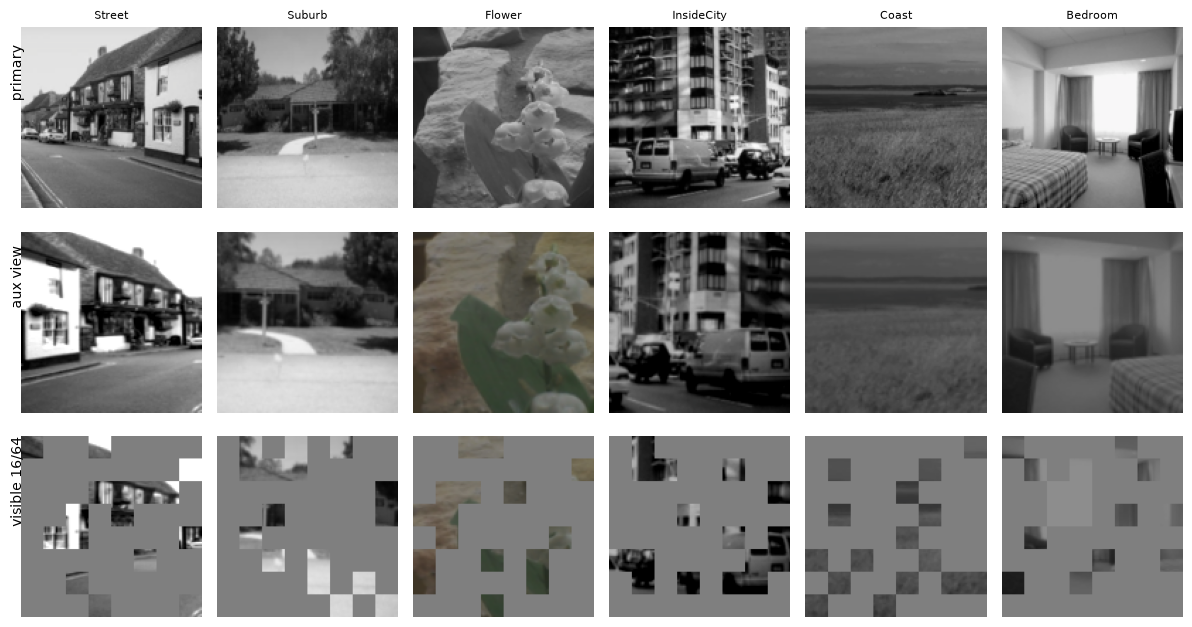

In [9]:
# Sanity check: primary view | auxiliary view | what the auxiliary stream actually sees (hidden patches grayed out)
def denorm(t):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (t.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

aux_tf = build_ssl_aug(BASE_CFG['crop_min'], BASE_CFG['jitter'], BASE_CFG['gray_p'])
pv = DataLoader(PairDS(train_subset, train_transform, aux_tf), batch_size=6, shuffle=True)
x1, x2, y = next(iter(pv))
p = BASE_CFG['patch']; g = IMG_SIZE // p; N = g * g; K = max(1, int(round(N * BASE_CFG['keep'])))
_, _, m = make_masks(6, N, K)
fig, axes = plt.subplots(3, 6, figsize=(12, 6.4))
for i in range(6):
    mk = m[i].reshape(g, g).repeat_interleave(p, 0).repeat_interleave(p, 1).unsqueeze(-1).numpy()
    axes[0, i].imshow(denorm(x1[i])); axes[0, i].set_title(class_names[y[i].item()], fontsize=8)
    axes[1, i].imshow(denorm(x2[i]))
    axes[2, i].imshow(denorm(x2[i]) * (1 - mk) + 0.5 * mk)
    for r in range(3): axes[r, i].axis('off')
axes[0, 0].text(-8, 32, 'primary', rotation=90, va='center'); axes[1, 0].text(-8, 32, 'aux view', rotation=90, va='center')
axes[2, 0].text(-8, 32, f'visible {K}/{N}', rotation=90, va='center')
plt.tight_layout(); plt.show()

## Model
A small ViT (pre-norm transformer, learned positional embeddings, CLS token) plus an MAE-style decoder used only by the auxiliary stream. Attention is written out explicitly (matmul + softmax, 4-D tensors only) and patch selection is done with one-hot matmuls, to stay on operations that DirectML handles reliably.

In [10]:
class Attention(nn.Module):
    def __init__(self, dim, heads, drop=0.0):
        super().__init__()
        self.heads, self.scale = heads, (dim // heads) ** -0.5
        self.qkv, self.proj, self.drop = nn.Linear(dim, dim * 3), nn.Linear(dim, dim), nn.Dropout(drop)

    def forward(self, x):
        B, N, C = x.shape
        q, k, v = [t.reshape(B, N, self.heads, C // self.heads).transpose(1, 2) for t in self.qkv(x).chunk(3, dim=-1)]
        attn = ((q @ k.transpose(-2, -1)) * self.scale).softmax(dim=-1)
        return self.drop(self.proj((attn @ v).transpose(1, 2).reshape(B, N, C)))

class Block(nn.Module):
    def __init__(self, dim, heads, drop=0.0, mlp_ratio=4):
        super().__init__()
        self.n1, self.attn, self.n2 = nn.LayerNorm(dim), Attention(dim, heads, drop), nn.LayerNorm(dim)
        self.mlp = nn.Sequential(nn.Linear(dim, dim * mlp_ratio), nn.GELU(), nn.Dropout(drop),
                                 nn.Linear(dim * mlp_ratio, dim), nn.Dropout(drop))

    def forward(self, x):
        x = x + self.attn(self.n1(x))
        return x + self.mlp(self.n2(x))

class ViTSSAT(nn.Module):
    def __init__(self, img=IMG_SIZE, patch=8, dim=192, depth=6, heads=3, dec_dim=128, dec_depth=2, dec_heads=4,
                 drop=0.1, num_classes=None):
        super().__init__()
        num_classes = num_classes or globals()['num_classes']
        self.N, self.patch = (img // patch) ** 2, patch
        # shared encoder
        self.patch_embed = nn.Conv2d(3, dim, kernel_size=patch, stride=patch)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, self.N + 1, dim))
        self.blocks = nn.ModuleList([Block(dim, heads, drop) for _ in range(depth)])
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, num_classes)                      # primary stream
        # auxiliary stream (training only)
        self.dec_embed = nn.Linear(dim, dec_dim)
        self.mask_token = nn.Parameter(torch.zeros(1, 1, dec_dim))
        self.dec_pos = nn.Parameter(torch.zeros(1, self.N, dec_dim))
        self.dec_blocks = nn.ModuleList([Block(dec_dim, dec_heads, 0.0) for _ in range(dec_depth)])
        self.dec_norm = nn.LayerNorm(dec_dim)
        self.dec_pred = nn.Linear(dec_dim, patch * patch * 3)
        for q in (self.cls_token, self.pos_embed, self.dec_pos):
            nn.init.trunc_normal_(q, std=0.02)
        nn.init.normal_(self.mask_token, std=0.02)
        self.apply(self._init)

    @staticmethod
    def _init(m):
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            nn.init.zeros_(m.bias)

    def _tokens(self, x):
        return self.patch_embed(x).flatten(2).transpose(1, 2) + self.pos_embed[:, 1:]

    def _encode(self, t):
        z = torch.cat([(self.cls_token + self.pos_embed[:, :1]).expand(t.size(0), -1, -1), t], dim=1)
        for b in self.blocks:
            z = b(z)
        return self.norm(z)

    def forward(self, x):                                            # primary stream: class logits (used by evaluate())
        return self.head(self._encode(self._tokens(x))[:, 0])

    def aux_loss(self, xa, target, sel, unshuf, mask):               # auxiliary stream: reconstruct hidden patches
        vis = self._encode(sel @ self._tokens(xa))[:, 1:]            # encoder sees only the visible patches
        d = self.dec_embed(vis)
        B, K, _ = d.shape
        full = unshuf @ torch.cat([d, self.mask_token.expand(B, self.N - K, -1)], dim=1) + self.dec_pos
        for b in self.dec_blocks:
            full = b(full)
        pred = self.dec_pred(self.dec_norm(full))
        return (((pred - target) ** 2).mean(-1) * mask).sum() / mask.sum()      # MSE on hidden patches only


def vit_kwargs(cfg):
    return {k: cfg[k] for k in ('patch', 'dim', 'depth', 'heads', 'dec_dim', 'dec_depth', 'dec_heads', 'drop')}

_m = ViTSSAT(**vit_kwargs(BASE_CFG))
n_enc = sum(p.numel() for n, p in _m.named_parameters() if not n.startswith(('dec_', 'mask_token')))
n_dec = sum(p.numel() for n, p in _m.named_parameters() if n.startswith(('dec_', 'mask_token')))
print(f'Encoder + classifier: {n_enc/1e6:.2f}M params | decoder (training only): {n_dec/1e6:.2f}M | tokens per image: {_m.N}')
del _m

Encoder + classifier: 2.83M params | decoder (training only): 0.53M | tokens per image: 64


## Training utilities

In [11]:
@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    correct, total, running_loss = 0, 0, 0.0
    criterion = nn.CrossEntropyLoss()
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        running_loss += criterion(logits, labels).item() * images.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total

In [12]:
# ---- Checkpoint helpers ----
CKPT_DIR = PROJECT_ROOT / 'checkpoints'
CKPT_DIR.mkdir(exist_ok=True)

def slug(name):
    """'SigLIP CNN final s0' -> 'siglip_cnn_final_s0'"""
    return ''.join(c.lower() if c.isalnum() else '_' for c in name).strip('_')

def cpu_state(sd):
    """Detached CPU copy of a state dict (safe to keep around and to save)."""
    return {k: v.detach().cpu().clone() for k, v in sd.items()}

def save_ckpt(name, stage, best_state, last_state, **extra):
    """Write checkpoints/<slug>_<stage>.pt (temp file first, so a crash can't corrupt the old one)."""
    path = CKPT_DIR / f'{slug(name)}_{stage}.pt'
    tmp = path.with_suffix('.tmp')
    torch.save({'best_state': best_state, 'last_state': last_state, **extra}, tmp)
    tmp.replace(path)
    return path

def load_ckpt(name, stage, which='best'):
    ck = torch.load(CKPT_DIR / f'{slug(name)}_{stage}.pt', map_location='cpu')
    return ck[f'{which}_state'], ck          # which = 'best' or 'last'

def load_pretrained(name, which='best'):
    """Rebuild a pretrained SSLNet (encoder + projection head) from a checkpoint."""
    sd, ck = load_ckpt(name, 'pretrain', which)
    net = SSLNet(**ck['hparams'].get('net_kwargs', {}))
    net.load_state_dict(sd)
    return net.to(device)

def load_finetuned(name, which='best'):
    """Rebuild a fine-tuned TNet classifier from a checkpoint."""
    sd, _ = load_ckpt(name, 'finetune', which)
    model = TNet(num_classes=num_classes)
    model.load_state_dict(sd)
    return model.to(device)

In [13]:
def train_vit(cfg, epochs, seed=SEED, name='', print_every=10):
    """Joint SSAT training (cfg['lam'] < 1) or plain supervised training (cfg['lam'] == 1.0).
    Returns (model with best-val weights, history, best_state, last_state, seconds)."""
    set_random_seed(seed)
    model = ViTSSAT(**vit_kwargs(cfg)).to(device)                    # built (and seeded) on CPU, then moved
    assert all(p.requires_grad for p in model.parameters()), 'some parameters are frozen'
    lam, use_aux = cfg['lam'], cfg['lam'] < 1.0
    mixing = cfg.get('mix', True)                                    # False -> no mixup/CutMix on the primary stream

    ds = PairDS(train_subset, train_transform, build_ssl_aug(cfg['crop_min'], cfg['jitter'], cfg['gray_p'])) if use_aux else train_dataset
    loader = Prefetch(DataLoader(ds, batch_size=cfg['bs'], shuffle=True, drop_last=True, num_workers=0, pin_memory=pin))

    decay = [p for n, p in model.named_parameters() if p.ndim >= 2 and 'pos' not in n and 'token' not in n]
    no_decay = [p for n, p in model.named_parameters() if not (p.ndim >= 2 and 'pos' not in n and 'token' not in n)]
    opt = optim.AdamW([{'params': decay, 'weight_decay': cfg['wd']}, {'params': no_decay, 'weight_decay': 0.0}], lr=cfg['lr'])
    warm = min(cfg['warmup'], max(epochs - 1, 1))
    sched = optim.lr_scheduler.LambdaLR(opt, lambda e: (e + 1) / warm if e < warm
                                        else 0.5 * (1 + math.cos(math.pi * (e - warm) / max(epochs - warm, 1))))
    criterion = nn.CrossEntropyLoss()

    hist = {'train_loss': [], 'cls_loss': [], 'aux_loss': [], 'val_loss': [], 'val_acc': []}
    best_acc, best_epoch, best_state, start = -1.0, 0, None, time.time()
    for ep in range(1, epochs + 1):
        model.train()
        tot = cls_tot = aux_tot = 0.0
        n = 0
        for batch in loader:
            if use_aux:
                x, xa, y = batch
            else:
                x, y = batch
            x, y = x.to(device), y.to(device)

            use_cutmix = mixing and CUTMIX_PROB > 0 and np.random.rand() < CUTMIX_PROB       # at most one mixing method per batch
            use_mixup = mixing and (not use_cutmix) and MIXUP_ALPHA > 0
            if use_cutmix:
                x, ya, yb, mix_lam = cutmix_data(x, y, alpha=CUTMIX_ALPHA)
            elif use_mixup:
                x, ya, yb, mix_lam = mixup_data(x, y, alpha=MIXUP_ALPHA)
            logits = model(x)
            l_cls = mixup_criterion(criterion, logits, ya, yb, mix_lam) if (use_cutmix or use_mixup) else criterion(logits, y)

            if use_aux:
                l_aux = model.aux_loss(*aux_batch(xa, cfg['patch'], cfg['keep']))     # aux view is NOT mixed
                loss = lam * l_cls + (1 - lam) * l_aux
                aux_tot += l_aux.item()
            else:
                loss = l_cls
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            tot += loss.item(); cls_tot += l_cls.item(); n += 1
        sched.step()
        vl, va = evaluate(model, val_loader, device)
        for k, v in zip(hist, (tot / n, cls_tot / n, aux_tot / n, vl, va)):
            hist[k].append(v)
        if va > best_acc:
            best_acc, best_epoch, best_state = va, ep, cpu_state(model.state_dict())
        if ep % print_every == 0 or ep == epochs:
            print(f'[{name}] ep {ep:03d}/{epochs} | loss {tot/n:.4f} (cls {cls_tot/n:.3f}, aux {aux_tot/n:.3f}) | '
                  f'val acc {va:.4f} (best {best_acc:.4f} @ {best_epoch}) | {time.time()-start:.0f}s')
    last_state = cpu_state(model.state_dict())
    model.load_state_dict(best_state)                                 # in-place copy: parameters stay trainable
    return model, hist, best_state, last_state, time.time() - start


def load_vit(name, which='best'):
    sd, ck = load_ckpt(name, 'train', which)
    model = ViTSSAT(**vit_kwargs(ck['hparams']['cfg']))
    model.load_state_dict(sd)
    return model.to(device)

In [14]:
# Bookkeeping for the final models
results = {}      # name -> dict of validation numbers
models = {}       # name -> trained model (best-val weights), for the test-set evaluation at the end
probe_logs = {}   # name -> SSL pretraining log

def record(name, history, model, probe_acc=None, note=''):
    results[name] = {'val_best': max(history['val_acc']), 'val_last': history['val_acc'][-1],
                     'probe_val': probe_acc, 'note': note}
    models[name] = model
    print(f"Logged '{name}': best val {results[name]['val_best']:.4f}, last val {results[name]['val_last']:.4f}")

## Step 0: Controls
Random-chance reference, plus a short **speed and shape check** of both streams on the device (it also tells you roughly how long a 60-epoch run will take before you commit to the ablations).

In [15]:
print(f'Chance accuracy: {1/num_classes:.4f}\n')
set_random_seed(SEED)
m = ViTSSAT(**vit_kwargs(BASE_CFG)).to(device)
opt = optim.AdamW(m.parameters(), lr=1e-4)
xb = torch.randn(BASE_CFG['bs'], 3, IMG_SIZE, IMG_SIZE)
yb = torch.randint(0, num_classes, (BASE_CFG['bs'],))
steps_per_epoch = len(train_dataset) // BASE_CFG['bs']

def time_steps(use_aux, n=6):
    ts = []
    for i in range(n):
        t0 = time.time()
        loss = F.cross_entropy(m(xb.to(device)), yb.to(device))
        if use_aux:
            loss = loss + m.aux_loss(*aux_batch(xb, BASE_CFG['patch'], BASE_CFG['keep']))
        opt.zero_grad(); loss.backward(); opt.step(); loss.item()
        ts.append(time.time() - t0)
    return np.mean(ts[2:])        # skip warm-up steps

t_sup, t_ssat = time_steps(False), time_steps(True)
print(f'supervised step: {t_sup*1000:.0f} ms -> ~{t_sup*steps_per_epoch:.1f} s/epoch (GPU part only)')
print(f'SSAT step:       {t_ssat*1000:.0f} ms -> ~{t_ssat*steps_per_epoch:.1f} s/epoch (GPU part only)')
print(f'Rough budget: Stage A {len(LR_GRID)+1} sup runs + Stage B ~6 SSAT runs at {ABL_EPOCHS} epochs = '
      f'~{((len(LR_GRID)+1)*t_sup + 6*t_ssat)*steps_per_epoch*ABL_EPOCHS/60:.0f} min (+ data/eval overhead)')
del m, opt
gc.collect()

Chance accuracy: 0.0625



c:\Users\Bryan\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\optim\adamw.py:529: UserWarning: The operator 'aten::lerp.Scalar_out' is not currently supported on the DML backend and will fall back to run on the CPU. This may have performance implications. (Triggered internally at C:\__w\1\s\pytorch-directml-plugin\torch_directml\csrc\dml\dml_cpu_fallback.cpp:17.)
  torch._foreach_lerp_(device_exp_avgs, device_grads, 1 - beta1)


supervised step: 1618 ms -> ~48.6 s/epoch (GPU part only)
SSAT step:       3245 ms -> ~97.3 s/epoch (GPU part only)
Rough budget: Stage A 3 sup runs + Stage B ~6 SSAT runs at 60 epochs = ~730 min (+ data/eval overhead)


0

## Stage A: tune the *supervised* ViT first
SSAT will get several tuning runs, so the baseline gets some too — otherwise a gain could just be a better learning rate. Results are saved to JSON after each run (re-running resumes). A different LR is adopted only if it beats the base LR by ≥ `MIN_GAIN`.

In [16]:
if not FINALS_ONLY:
    ABL_FILE = CKPT_DIR / f'{PREFIX}vit_ablation_{ABL_EPOCHS}ep.json'
    abl = json.loads(ABL_FILE.read_text()) if (ABL_FILE.exists() and not FORCE_RERUN) else {}

    def run_ablation(name, knob, value, cfg, seed=SEED):
        if name in abl:
            print(f'[{name}] already done -> skipping (score {abl[name]["score"]:.4f})')
            return
        try:
            model, hist, _, _, secs = train_vit(cfg, ABL_EPOCHS, seed=seed, name=name, print_every=ABL_EPOCHS)
        except RuntimeError as e:                 # e.g. DirectML out-of-memory
            print(f'[{name}] FAILED: {str(e)[:150]}')
            gc.collect()
            return
        abl[name] = dict(knob=knob, value=value, seed=seed, cfg=cfg, epochs=ABL_EPOCHS,
                         score=float(np.mean(hist['val_acc'][-SCORE_LAST:])), val_best=max(hist['val_acc']),
                         val_last=hist['val_acc'][-1], aux_last=hist['aux_loss'][-1], seconds=secs)
        ABL_FILE.write_text(json.dumps(abl, indent=1))
        del model
        gc.collect()
        print(f'[{name}] done in {secs/60:.1f} min | score {abl[name]["score"]:.4f} | best {abl[name]["val_best"]:.4f}\n')

    SUP = lambda cfg: {**cfg, 'lam': 1.0}
    lrs = sorted(set([BASE_CFG['lr']] + LR_GRID))
    t_start = time.time()
    for lr in lrs:
        run_ablation(f'sup lr={lr}', 'lr', lr, SUP({**BASE_CFG, 'lr': lr}))
    print(f'Stage A wall time this session: {(time.time()-t_start)/60:.1f} min')

    ref = abl.get(f"sup lr={BASE_CFG['lr']}")
    best_lr = BASE_CFG['lr']
    if ref is not None:
        cands = [(abl[f'sup lr={lr}']['score'], lr) for lr in lrs if f'sup lr={lr}' in abl]
        best_score, cand_lr = max(cands)
        if cand_lr != BASE_CFG['lr'] and best_score - ref['score'] >= MIN_GAIN:
            best_lr = cand_lr
    for lr in lrs:
        if f'sup lr={lr}' in abl:
            print(f"  lr={lr:<8} score {abl[f'sup lr={lr}']['score']:.4f}" + ('   <-- chosen' if lr == best_lr else ''))
    BASE_CFG['lr'] = best_lr
    print('Supervised ViT / SSAT learning rate:', best_lr)
else:
    SUP = lambda cfg: {**cfg, 'lam': 1.0}

## Stage B: SSAT ablations (one knob at a time, 60 epochs)
Base SSAT = `λ = 0.5`, 25% visible patches. `λ` sets how much the reconstruction task competes with classification; the visible ratio sets how hard the reconstruction is. Names include the LR so results from a different LR are never mixed up on resume.

In [17]:
if not FINALS_ONLY:
    tag = f"lr={BASE_CFG['lr']}"
    t_start = time.time()
    run_ablation(f'ssat base {tag}', 'base', None, BASE_CFG)
    if RUN_NOISE_CHECK:
        run_ablation(f'ssat base (seed 1) {tag}', 'base', None, BASE_CFG, seed=SEED + 1)
    for knob, values in GRID.items():
        for v in values:
            if v == BASE_CFG[knob]:
                continue
            run_ablation(f'ssat {knob}={v} {tag}', knob, v, {**BASE_CFG, knob: v})
    print(f'Stage B wall time this session: {(time.time()-t_start)/60:.1f} min')

In [18]:
if not FINALS_ONLY:
    # Ablation table + chart
    sup_ref = abl.get(f'sup {tag}', {}).get('score')
    base_score = abl[f'ssat base {tag}']['score']
    noise_run = abl.get(f'ssat base (seed 1) {tag}')
    print(f"Supervised ViT (same LR): {sup_ref if sup_ref is None else round(sup_ref, 4)} | SSAT base: {base_score:.4f}"
          + (f" | SSAT base seed gap: {abs(base_score - noise_run['score']):.4f}" if noise_run else ''))
    print(f"\n{'run':<34}{'score (last5)':>14}{'val best':>10}{'vs SSAT base':>14}{'aux loss':>10}{'min':>7}")
    for name, r in abl.items():
        if not (name.startswith('ssat') and name.endswith(tag)) and not name.startswith(('sup', 'combined')):
            continue
        d = r['score'] - base_score
        flag = '  <-- adopt?' if (name.startswith('ssat') and r['knob'] not in ('base', 'lr') and d >= MIN_GAIN) else ''
        print(f"{name:<34}{r['score']:>14.4f}{r['val_best']:>10.4f}{d:>+14.4f}{r['aux_last']:>10.3f}{r['seconds']/60:>7.1f}{flag}")

    knobs = [k for k in GRID if any(f'ssat {k}={v} {tag}' in abl for v in GRID[k])]
    if knobs:
        fig, axes = plt.subplots(1, len(knobs), figsize=(3.2 * len(knobs), 3.4), sharey=True)
        axes = np.atleast_1d(axes)
        for ax, k in zip(axes, knobs):
            pts = [(v, abl[f'ssat {k}={v} {tag}']['score']) for v in GRID[k] if f'ssat {k}={v} {tag}' in abl] + [(BASE_CFG[k], base_score)]
            pts.sort(key=lambda q: q[0])
            ax.plot([str(q[0]) for q in pts], [q[1] for q in pts], marker='o')
            ax.axhspan(base_score - MIN_GAIN, base_score + MIN_GAIN, color='gray', alpha=0.2)
            if sup_ref is not None:
                ax.axhline(sup_ref, color='red', ls=':', lw=1)
            ax.set_title(k)
        axes[0].set_ylabel('val acc (mean last 5)')
        plt.suptitle('Gray band = SSAT base +/- MIN_GAIN (tie); red dotted = supervised ViT', fontsize=9)
        plt.tight_layout(); plt.show()

## Combine, then choose the final configs
A knob is adopted only if its best alternative beats the SSAT base by ≥ `MIN_GAIN`. A combination is re-run and kept only if at least as good as the base. The **final SSAT config can still lose to the supervised ViT** — that is a legitimate result, and the final runs report it either way.

In [19]:
if not FINALS_ONLY:
    chosen = {}
    for knob, values in GRID.items():
        cands = [(abl[f'ssat {knob}={v} {tag}']['score'], v) for v in values if f'ssat {knob}={v} {tag}' in abl]
        if cands:
            best_score, best_v = max(cands)
            if best_score - base_score >= MIN_GAIN:
                chosen[knob] = best_v
    chosen.update(MANUAL_OVERRIDE)
    print('Knobs adopted:', chosen if chosen else 'none (SSAT base kept)')

    FINAL_SSAT_CFG = dict(BASE_CFG)
    if chosen:
        run_ablation(f'combined {tag}', 'combined', str(chosen), {**BASE_CFG, **chosen})
        comb = abl.get(f'combined {tag}')
        if comb is not None and comb['score'] >= base_score:
            FINAL_SSAT_CFG = {**BASE_CFG, **chosen}
            print(f"Combined ({comb['score']:.4f}) >= base ({base_score:.4f}) -> using the combined config")
        else:
            print('Combined config did not beat the base -> keeping the SSAT base')
    FINAL_SUP_CFG = SUP(BASE_CFG)
    (CKPT_DIR / f'{PREFIX}vit_final_cfgs.json').write_text(json.dumps({'ssat': FINAL_SSAT_CFG, 'sup': FINAL_SUP_CFG}, indent=1))
    print('FINAL_SSAT_CFG:', FINAL_SSAT_CFG)

    sec_per_ep = abl[f'ssat base {tag}']['seconds'] / ABL_EPOCHS
    sup_sec = abl.get(f'sup {tag}', {}).get('seconds', sec_per_ep * ABL_EPOCHS) / ABL_EPOCHS
    print(f'\nMeasured ~{sec_per_ep:.1f} s/epoch (SSAT) and ~{sup_sec:.1f} s/epoch (supervised) -> final phase '
          f'~{(sec_per_ep + sup_sec) * FINAL_EPOCHS * len(FINAL_SEEDS) / 60:.0f} min for {len(FINAL_SEEDS)} seed(s) x 2 models.')
else:
    _p = 'smoke_' if (SMOKE_TEST and (CKPT_DIR / 'smoke_vit_final_cfgs.json').exists()) else ''
    _cfgs = json.loads((CKPT_DIR / f'{_p}vit_final_cfgs.json').read_text())           # selected by the 64px notebook
    FINAL_SSAT_CFG = {**_cfgs['ssat'], 'patch': BASE_CFG['patch']}
    FINAL_SUP_CFG = {**_cfgs['sup'], 'patch': BASE_CFG['patch']}
    BASE_CFG['lr'] = FINAL_SSAT_CFG['lr']
    print('FINALS_ONLY: using the 64px recipe at', IMG_SIZE, 'px, patch', BASE_CFG['patch'], '->', FINAL_SSAT_CFG)

FINALS_ONLY: using the 64px recipe at 128 px, patch 16 -> {'lam': 0.5, 'keep': 0.25, 'lr': 0.00025, 'wd': 0.05, 'bs': 64, 'warmup': 5, 'drop': 0.1, 'crop_min': 0.5, 'jitter': 0.4, 'gray_p': 0.2, 'patch': 16, 'dim': 192, 'depth': 6, 'heads': 3, 'dec_dim': 128, 'dec_depth': 2, 'dec_heads': 4}


## Final runs
Both models train for `FINAL_EPOCHS` with identical encoder, data and schedule; only `λ` (and the auxiliary stream it switches on) differs. Checkpoints: `checkpoints/vit_{sup,ssat}_final_s{seed}_train.pt` (best-val and last weights).

In [20]:
def run_final(kind, cfg, seed, tag='', epochs=None):
    """Train (or, if an identical finished run is already on disk, just load) one final model."""
    epochs = epochs or FINAL_EPOCHS
    name = f'{PREFIX}ViT {kind} final{tag} s{seed}'
    if (CKPT_DIR / f'{slug(name)}_train.pt').exists():
        _, ck = load_ckpt(name, 'train')
        if ck['hparams'].get('epochs') == epochs and ck['hparams'].get('cfg') == cfg:
            record(name, ck['history'], load_vit(name), note=f'loaded from checkpoint (lam={cfg["lam"]}, seed {seed})')
            return ck['history']
    model, hist, best, last, secs = train_vit(cfg, epochs, seed=seed, name=name, print_every=10)
    save_ckpt(name, 'train', best, last, history=hist, hparams=dict(cfg=cfg, epochs=epochs, seed=seed))
    record(name, hist, model, note=f'lam={cfg["lam"]}, keep={cfg["keep"]}, seed {seed}, {secs/60:.1f} min')
    return hist

final_hists = {}
for s in FINAL_SEEDS:
    final_hists[('sup', s)] = run_final('sup', FINAL_SUP_CFG, s)
    final_hists[('SSAT', s)] = run_final('SSAT', FINAL_SSAT_CFG, s)

[128px_ViT sup final s0] ep 010/100 | loss 2.3627 (cls 2.363, aux 0.000) | val acc 0.3667 (best 0.3667 @ 10) | 502s
[128px_ViT sup final s0] ep 020/100 | loss 2.2281 (cls 2.228, aux 0.000) | val acc 0.4396 (best 0.4396 @ 20) | 1000s
[128px_ViT sup final s0] ep 030/100 | loss 2.0338 (cls 2.034, aux 0.000) | val acc 0.4917 (best 0.5000 @ 28) | 1501s
[128px_ViT sup final s0] ep 040/100 | loss 1.8252 (cls 1.825, aux 0.000) | val acc 0.5292 (best 0.5333 @ 37) | 2004s
[128px_ViT sup final s0] ep 050/100 | loss 1.8019 (cls 1.802, aux 0.000) | val acc 0.5458 (best 0.5458 @ 50) | 2494s
[128px_ViT sup final s0] ep 060/100 | loss 1.6941 (cls 1.694, aux 0.000) | val acc 0.5625 (best 0.5729 @ 57) | 2982s
[128px_ViT sup final s0] ep 070/100 | loss 1.4373 (cls 1.437, aux 0.000) | val acc 0.5500 (best 0.5729 @ 57) | 3498s
[128px_ViT sup final s0] ep 080/100 | loss 1.5294 (cls 1.529, aux 0.000) | val acc 0.5375 (best 0.5729 @ 57) | 4028s
[128px_ViT sup final s0] ep 090/100 | loss 1.5646 (cls 1.565, aux

## Round 2: improve the ViT recipe (supervised ViT first)
The v1 ViT looked **undertrained**: validation accuracy and the classification loss were still improving at the end, it got only 3,000 optimizer steps, and its LR grid hit the lower edge (the best LR was the smallest tried). Round 2 tests three changes on the **supervised** ViT only (60 epochs, same scoring as Stage A), one at a time against the v1 recipe, then combines the winners:
- `lr = 1e-4` (lower than the old best, 2.5e-4)
- `mix = False` (no mixup/CutMix: the CNN-style regularization may be too strong for an underfit model)
- `bs = 32` (twice the optimizer steps per epoch)

A change is adopted only if it beats the v1 supervised score by >= `MIN_GAIN`. SSAT then inherits the same recipe (its `lam=0.5`, `keep=0.25` base config, since every Stage B knob was within noise). Re-running this notebook from the top is cheap: Stage A/B and the v1 finals reload from disk.

In [21]:
if not FINALS_ONLY:
    RUN_ROUND2 = True
    FINAL_EPOCHS_V2 = 150         # more epochs: the v1 curves were still rising at epoch 100
    C_RUNS = {                    # name -> overrides of the v1 recipe
        'lr=0.0001': dict(lr=1e-4),
        'nomix':     dict(mix=False),
        'bs=32':     dict(bs=32),
    }
    if SMOKE_TEST:
        C_RUNS = dict(list(C_RUNS.items())[:1])
        FINAL_EPOCHS_V2 = 2

    REF_C = SUP(BASE_CFG)                                  # v1 supervised recipe
    ref_score = abl[f"sup lr={BASE_CFG['lr']}"]['score']
    t_start = time.time()
    for nm, ov in C_RUNS.items():
        run_ablation(f'C sup {nm}', 'C', nm, {**REF_C, **ov})
    print(f'Round-2 search wall time this session: {(time.time()-t_start)/60:.1f} min')

    print(f'\nv1 supervised reference (score = mean of last {SCORE_LAST} val accs): {ref_score:.4f}')
    cand = {}
    for nm, ov in C_RUNS.items():
        r = abl.get(f'C sup {nm}')
        if r is None:
            continue
        d = r['score'] - ref_score
        print(f"  {nm:<12} score {r['score']:.4f} | best {r['val_best']:.4f} | delta {d:+.4f} | {r['seconds']/60:.1f} min" + ('   <-- adopt' if d >= MIN_GAIN else ''))
        if d >= MIN_GAIN:
            cand[nm] = (r['score'], ov)
    if len(cand) > 1:
        merged = {}
        for _, ov in cand.values():
            merged.update(ov)
        run_ablation('C sup combined', 'C', 'combined', {**REF_C, **merged})
        rc = abl.get('C sup combined')
        if rc is not None:
            print(f"  {'combined':<12} score {rc['score']:.4f} | best {rc['val_best']:.4f} | delta {rc['score'] - ref_score:+.4f}")
            cand['combined'] = (rc['score'], merged)
    if cand:
        best_nm = max(cand, key=lambda k: cand[k][0])
        V2_OV = cand[best_nm][1]
        print('\nRound-2 recipe:', best_nm, V2_OV)
    else:
        V2_OV = None
        print('\nNo change beat the v1 recipe by MIN_GAIN -> keeping v1; the v2 final runs are skipped.')
else:
    V2_OV = None
    RUN_ROUND2 = False

In [22]:
if V2_OV is not None and RUN_ROUND2:
    FINAL_SUP_CFG2 = SUP({**BASE_CFG, **V2_OV})
    FINAL_SSAT_CFG2 = {**BASE_CFG, **V2_OV}
    (CKPT_DIR / f'{PREFIX}vit_final_cfgs_v2.json').write_text(json.dumps({'ssat': FINAL_SSAT_CFG2, 'sup': FINAL_SUP_CFG2}, indent=1))
    sup_sec = abl[f'C sup {best_nm}']['seconds'] / ABL_EPOCHS
    est = sup_sec * (1 + 1.75) * FINAL_EPOCHS_V2 * len(FINAL_SEEDS) / 60      # SSAT ~1.75x a supervised epoch (v1 timings)
    print(f'Projected v2 final phase: ~{est:.0f} min for {len(FINAL_SEEDS)} seed(s) x 2 models at {FINAL_EPOCHS_V2} epochs')
    for s in FINAL_SEEDS:
        final_hists[('sup v2', s)] = run_final('sup', FINAL_SUP_CFG2, s, tag=' v2', epochs=FINAL_EPOCHS_V2)
        final_hists[('SSAT v2', s)] = run_final('SSAT', FINAL_SSAT_CFG2, s, tag=' v2', epochs=FINAL_EPOCHS_V2)

## Results (validation)

Experiment                      val best  val last   note
128px_ViT sup final s0            0.5750    0.5625   lam=1.0, keep=0.25, seed 0, 84.5 min
128px_ViT SSAT final s0           0.6083    0.6021   lam=0.5, keep=0.25, seed 0, 159.6 min
128px_ViT sup final s1            0.5875    0.5687   lam=1.0, keep=0.25, seed 1, 80.0 min
128px_ViT SSAT final s1           0.6125    0.5792   lam=0.5, keep=0.25, seed 1, 158.7 min

v1 seed 0: SSAT - supervised = +0.0333 (best-val)  |  +0.0396 (last epoch)
v1 seed 1: SSAT - supervised = +0.0250 (best-val)  |  +0.0104 (last epoch)
(Gaps under ~2-3 pts are within validation noise; two seeds are not enough to prove a small gain.)


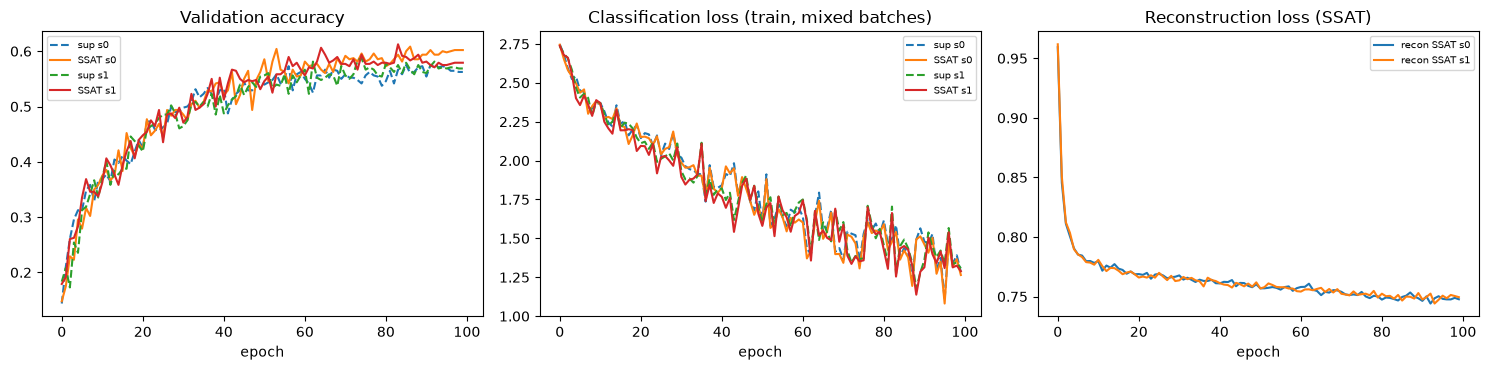

In [23]:
print(f"{'Experiment':<30}{'val best':>10}{'val last':>10}   note")
for name, r in results.items():
    print(f"{name:<30}{r['val_best']:>10.4f}{r['val_last']:>10.4f}   {r['note']}")

print()
for tag in ('', ' v2'):
    for s in FINAL_SEEDS:
        a, b = results.get(f'{PREFIX}ViT sup final{tag} s{s}'), results.get(f'{PREFIX}ViT SSAT final{tag} s{s}')
        if a and b:
            print(f"{'v2' if tag else 'v1'} seed {s}: SSAT - supervised = {b['val_best'] - a['val_best']:+.4f} (best-val)  |  {b['val_last'] - a['val_last']:+.4f} (last epoch)")
print('(Gaps under ~2-3 pts are within validation noise; two seeds are not enough to prove a small gain.)')

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for (kind, s), h in final_hists.items():
    ls = '-' if kind.startswith('SSAT') else '--'
    ax[0].plot(h['val_acc'], ls, label=f'{kind} s{s}')
    ax[1].plot(h['cls_loss'], ls, label=f'{kind} s{s}')
    if kind.startswith('SSAT'):
        ax[2].plot(h['aux_loss'], label=f'recon {kind} s{s}')
ax[0].set_title('Validation accuracy'); ax[1].set_title('Classification loss (train, mixed batches)'); ax[2].set_title('Reconstruction loss (SSAT)')
for a in ax: a.set_xlabel('epoch'); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

## Experiment log (fill this in)

| Experiment | What changed? | Why did you try it? | Val acc | Test acc | What did you learn? |
|---|---|---|---|---|---|
| Supervised ViT (λ=1) | Nothing | Baseline for SSAT | | | |
| sup lr 2.5e-4 / 1e-3 | LR | Fair baseline | | | |
| SSAT base (λ=0.5, 25% visible) | Add reconstruction stream | Slides: SSAT helps ViTs on small data | | | |
| λ 0.8 / 0.2 | Weight of the aux loss | | | | |
| keep 12.5% / 50% | Visible patches | Harder / easier reconstruction | | | |
| Final v1 (100 ep, 2 seeds) | | | | | |
| Round 2: lr 1e-4 / no mixup / bs 32 | Supervised-ViT recipe | v1 ViT looked undertrained | | | |
| Final v2 (recipe from round 2) | | | | | |

## Final test-set evaluation and cross-model comparison
**Run once**, after all decisions are made on validation. The table below also loads the saved SigLIP-CNN and BYOL-CNN fine-tuned checkpoints (if present in `checkpoints/`) and evaluates them on test, so every method is reported the same way. That is reporting only — nothing was selected on these numbers.

In [24]:
def conv_bn_relu(in_ch, out_ch):
    return nn.Sequential(nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))

class TNet(nn.Module):              # only needed to load the CNN checkpoints for the comparison table
    def __init__(self, num_classes=16, widths=(32, 64, 128, 256), dropout=0.3):
        super().__init__()
        c1, c2, c3, c4 = widths
        self.features = nn.Sequential(
            conv_bn_relu(3, c1), conv_bn_relu(c1, c1), nn.MaxPool2d(2),
            conv_bn_relu(c1, c2), conv_bn_relu(c2, c2), nn.MaxPool2d(2),
            conv_bn_relu(c2, c3), conv_bn_relu(c3, c3), nn.MaxPool2d(2),
            conv_bn_relu(c3, c4), conv_bn_relu(c4, c4))
        self.classifier = nn.Sequential(nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten(), nn.Dropout(dropout), nn.Linear(c4, num_classes))
    def forward(self, x):
        return self.classifier(self.features(x))

rows = {}     # method -> list of (val_best, test_acc) over seeds
for label, kind, tag in [('ViT supervised (v1)', 'sup', ''), ('ViT SSAT (v1)', 'SSAT', ''),
                         ('ViT supervised (v2)', 'sup', ' v2'), ('ViT SSAT (v2)', 'SSAT', ' v2')]:
    for s in FINAL_SEEDS:
        n = f'{PREFIX}ViT {kind} final{tag} s{s}'
        if n in models:
            rows.setdefault(label, []).append((results[n]['val_best'], evaluate(models[n], test_loader, device)[1]))
for label, pn in [('SigLIP CNN (fine-tuned)', 'SigLIP CNN'), ('BYOL CNN (fine-tuned)', 'BYOL CNN')]:
    for s in (0, 1, 2):
        n = f'{PREFIX}{pn} final s{s}'
        try:
            _, ck = load_ckpt(n, 'finetune')
            rows.setdefault(label, []).append((max(ck['history']['val_acc']), evaluate(load_finetuned(n), test_loader, device)[1]))
        except FileNotFoundError:
            pass

print(f"{'Method':<26}{'seeds':>6}{'val best (mean)':>17}{'test acc (mean)':>17}{'test std':>10}")
for label, r in rows.items():
    v, t = np.array([a for a, _ in r]), np.array([b for _, b in r])
    print(f'{label:<26}{len(r):>6}{v.mean():>17.4f}{t.mean():>17.4f}{t.std():>10.4f}')
print('\nNot compute-matched: the CNN rows include 200 SSL epochs + 100 fine-tuning epochs; v1 ViT rows are 100 epochs, v2 rows use FINAL_EPOCHS_V2.')

C:\Users\Bryan\AppData\Local\Temp\ipykernel_12896\54230171.py:22: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ck = torch.load(CKPT_DIR / f'{slug(name)}_{stage}.pt', map_lo

Method                     seeds  val best (mean)  test acc (mean)  test std
ViT supervised (v1)            2           0.5813           0.5875    0.0125
ViT SSAT (v1)                  2           0.6104           0.5887    0.0088
SigLIP CNN (fine-tuned)        2           0.8917           0.8688    0.0062
BYOL CNN (fine-tuned)          2           0.8917           0.8588    0.0138

Not compute-matched: the CNN rows include 200 SSL epochs + 100 fine-tuning epochs; v1 ViT rows are 100 epochs, v2 rows use FINAL_EPOCHS_V2.


Validation (ViT SSAT, seed 0) overall accuracy: 0.6083

Class             Acc     N   Most confused with
Industrial      0.310    29   Store
Kitchen         0.333    30   Bedroom
Store           0.452    31   InsideCity
Bedroom         0.487    39   Kitchen
LivingRoom      0.500    26   Kitchen
InsideCity      0.500    30   Highway
Forest          0.552    29   Flower
OpenCountry     0.571    28   Coast
Mountain        0.643    28   Flower
TallBuilding    0.679    28   Industrial
Office          0.708    24   TallBuilding
Highway         0.750    28   Coast
Coast           0.758    33   OpenCountry
Street          0.781    32   Coast
Suburb          0.824    34   Bedroom
Flower          0.871    31   Forest


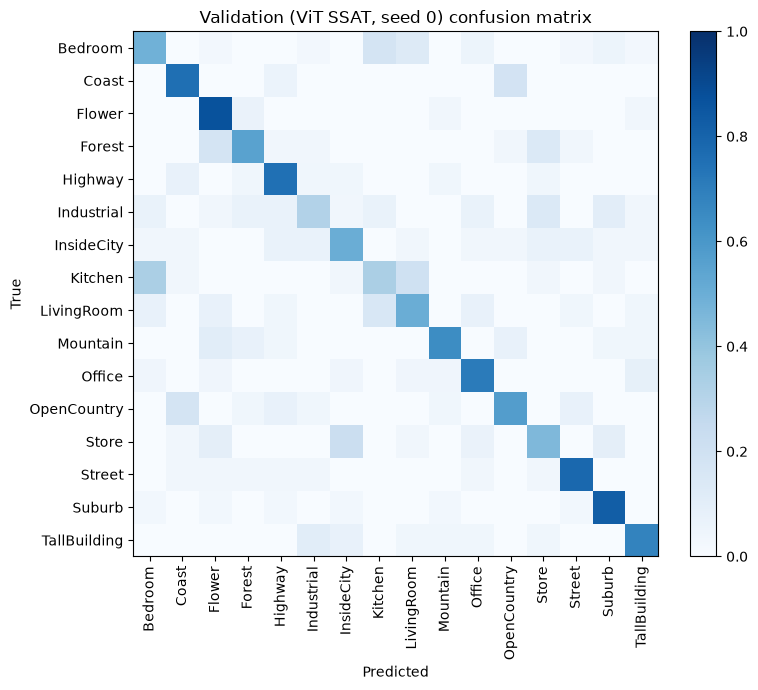

In [25]:
# Per-class analysis (from A1). Validation for decisions; switch to test_loader only for the final report.
@torch.no_grad()
def get_predictions(model, loader, device):
    model.eval()
    all_preds, all_labels = [], []
    for images, labels in loader:
        logits = model(images.to(device))
        all_preds.append(logits.argmax(dim=1).cpu())
        all_labels.append(labels)
    return torch.cat(all_preds).numpy(), torch.cat(all_labels).numpy()

def per_class_report(model, loader, class_names, device, title=''):
    preds, labels = get_predictions(model, loader, device)
    n = len(class_names)
    cm = np.zeros((n, n), dtype=int)           # rows = true class, cols = predicted class
    for t, p in zip(labels, preds):
        cm[t, p] += 1
    support = cm.sum(axis=1)
    per_class_acc = cm.diagonal() / np.maximum(support, 1)

    print(f'{title} overall accuracy: {(preds == labels).mean():.4f}\n')
    print(f'{"Class":<14}{"Acc":>7}{"N":>6}   Most confused with')
    for i in np.argsort(per_class_acc):        # worst classes first
        off = cm[i].copy(); off[i] = 0
        confused = class_names[off.argmax()] if off.sum() > 0 else '-'
        print(f'{class_names[i]:<14}{per_class_acc[i]:>7.3f}{support[i]:>6}   {confused}')

    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(cm / np.maximum(support[:, None], 1), cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(n)); ax.set_xticklabels(class_names, rotation=90)
    ax.set_yticks(range(n)); ax.set_yticklabels(class_names)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(f'{title} confusion matrix')
    plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()
    return cm, per_class_acc

cm_val, acc_val = per_class_report(models.get(f'{PREFIX}ViT SSAT final v2 s{FINAL_SEEDS[0]}', models.get(f'{PREFIX}ViT SSAT final s{FINAL_SEEDS[0]}')), val_loader, class_names, device, 'Validation (ViT SSAT, seed 0)')

## Notes for the write-up
- **The baseline is the point.** Report SSAT's gain as SSAT minus the supervised ViT trained with the same recipe and LR search, and say how many tuning runs each received.
- ViTs trained from scratch on 2,400 images are expected to trail the CNN; if SSAT narrows the gap that is the finding, even if it does not close it.
- Possible follow-ups: contrastive auxiliary tasks (the paper also tried SimCLR/DINO-style), a larger `λ` grid, longer training, deeper/wider encoder.